# Leak Detection — Point-of-Interest Baseline Experiments

The ANYbotics robot photographs the same points of interest (POIs) repeatedly. Instead of judging each image
in isolation, these experiments compare each image to **the same POI's normal (no-leak) history**.

| Model | Idea | Needs leak examples to train? |
|---|---|---|
| Current production model | `leak_suspected` from the table | — |
| A. Absolute features + LR | Existing 10 image features, logistic regression (prior best approach) | Yes |
| B1. POI-relative feature anomaly | How far each feature deviates from this POI's normal images | **No** |
| B2. POI-relative features + LR | Logistic regression on the POI-relative features | Yes |
| C1. DINOv2 global kNN | Embedding distance to nearest normal image of the same POI | **No** |
| C2. DINOv2 PatchCore-lite | Patch-level distance to the POI's normal patches (localizes the change) | **No** |
| D. Ensemble B1 + C2 | Average rank of B1 and C2 | **No** |

**Evaluation protocol (all models):**
- All 157 available images (6 leaks, ~4 leak events).
- **Leave-one-day-out**: an image is scored using only images from *other days*, so the 3 images of the
  POI 412 leak on 2026-09-08 never inform each other.
- POI reference = labeled-normal images of the same POI from other days (min 5); otherwise falls back to
  normal images from all POIs (applies to the single-image POIs, including the POI 358 leak).
- Primary metrics: **false alarms needed to catch k of 6 leaks**, and leaks caught under a fixed false-alarm
  budget (5% / 10% of normal images). No thresholds are tuned on the leak images.

In [0]:
%pip install -q mlflow scikit-learn scipy matplotlib pillow torch torchvision transformers
dbutils.library.restartPython()

Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


In [0]:
import os
import time
import json
import numpy as np
import pandas as pd
import mlflow
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, average_precision_score

# --- MLflow experiment: all model runs are logged here for side-by-side comparison ---
EXPERIMENT = "/Users/jeffrey.pao@databricks.com/Leak Detection - POI Baseline Experiments"
mlflow.set_experiment(EXPERIMENT)

# Source table: image metadata, ground-truth leak labels, and train/test splits
SPLITS_TABLE = "stable_classic_wg38i9_catalog.westlake_gas_leakage_2.silver_liquid_leak_results_splits"
# UC Volume containing the raw robot photographs
IMAGE_BASE_PATH = "/Volumes/stable_classic_wg38i9_catalog/westlake_gas_leakage_2/documents/OneDrive_1_10-13-2026/"
MIN_REF = 5      # Need at least this many same-POI normal images; fewer triggers fallback to all POIs
RNG = np.random.default_rng(42)

# Load the labeled dataset and keep only rows whose image file actually exists on disk
df = spark.table(SPLITS_TABLE).toPandas()
volume_files = set(os.listdir(IMAGE_BASE_PATH))
df = df[df["filename"].isin(volume_files)].drop_duplicates("filename").reset_index(drop=True)
# --- Derived columns ---
df["ts"] = pd.to_datetime(df["created_on_date_time"])
df["day"] = df["ts"].dt.strftime("%Y-%m-%d")       # Day string — used for leave-one-day-out CV splits
df["poi"] = df["point_of_interest_id"].astype(int)  # Physical location the robot photographed
df["y"] = (df["leaked"] == 1.0).astype(int)          # Ground-truth: 1 = confirmed leak
df["current_alert"] = (df["leak_suspected"] == "Yes").astype(int)  # Existing production model's prediction

y = df["y"].values
N_LEAKS = int(y.sum())
N_NORMAL = int((y == 0).sum())
print(f"{len(df)} images | {N_LEAKS} leaks | {N_NORMAL} normal | {df['poi'].nunique()} POIs | {df['day'].nunique()} days")
display(df[df.y == 1][["filename", "poi", "ts", "split", "leak_suspected"]])

If you are using MLflow Tracing, you can migrate your traces to Unity Catalog for unlimited storage, fine-grained access controls, and queryability from notebooks, SQL, and dashboards. Learn more: https://docs.databricks.com/aws/en/mlflow3/genai/tracing/migrate-traces-to-uc


156 images | 6 leaks | 150 normal | 13 POIs | 12 days


filename,poi,ts,split,leak_suspected
e197c9fb-60df-49f4-a878-7973109d55f7_measurement.jpg,412,2026-09-08T09:01:43.000Z,train,Yes
41e0d3c2-ce67-4429-85b8-672086935c20_measurement.jpg,413,2026-09-04T13:01:27.000Z,train,Yes
81a31228-e5e6-4638-9f12-8f052a12d247_measurement.jpg,358,2026-08-27T12:01:13.000Z,train,No
fd850fc0-58ad-47d7-8211-901a5eef3421_measurement.jpg,412,2026-09-08T10:01:37.000Z,train,No
6fe0911c-b724-48de-ad74-433e0ade43f6_measurement.jpg,412,2026-09-08T12:01:44.000Z,validation,No
053a36af-1f15-49d3-b59f-a97249dabedb_measurement.jpg,422,2026-09-14T20:01:15.000Z,test,Yes


In [0]:
# Pre-compute arrays used by every model for fast indexing
poi_arr = df["poi"].values    # POI id for each image
day_arr = df["day"].values    # Day string for each image
normal_arr = y == 0            # Boolean mask: True for non-leak images


def reference_idx(i, exclude_days=()):
    """For image i, return indices of its 'normal baseline' images.

    First tries normal images of the SAME POI from different days.
    If fewer than MIN_REF exist, falls back to normal images from ALL POIs.
    Returns (indices_array, used_fallback_bool)."""
    base = normal_arr & (day_arr != day_arr[i]) & ~np.isin(day_arr, list(exclude_days))
    same = base & (poi_arr == poi_arr[i])
    if same.sum() >= MIN_REF:
        return np.where(same)[0], False
    return np.where(base)[0], True


fallback = np.array([reference_idx(i)[1] for i in range(len(df))])
print(f"Images using all-POI fallback reference: {fallback.sum()} "
      f"(leaks: {int(y[fallback].sum())}, POIs: {sorted(set(poi_arr[fallback]))})")


def fp_at_recall(scores, y, k):
    """Key metric: how many false alarms must you accept to catch the top-k leaks?

    Sorts leak scores descending; sets threshold at the k-th leak's score,
    then counts how many normal images also exceed that threshold."""
    leak_scores = np.sort(scores[y == 1])[::-1]
    if k > len(leak_scores) or not np.isfinite(leak_scores[k - 1]):
        return np.nan
    thr = leak_scores[k - 1]
    return int(((scores >= thr) & (y == 0)).sum())


def at_threshold(scores, y, thr):
    """Compute confusion-matrix metrics (TP, FP, FN, TN, precision, recall, F1) at a fixed threshold."""
    pred = scores >= thr
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return dict(tp=tp, fp=fp, fn=fn, tn=tn, alerts=tp + fp, precision=prec, recall=rec, f1=f1)


def evaluate(scores, y):
    """Full evaluation suite for a model's anomaly scores.

    Computes: ROC-AUC, PR-AUC, false alarms needed to catch 3-6 of 6 leaks,
    and precision/recall at fixed false-alarm budgets (5% and 10% of normals).
    Budget thresholds are set from normal-image score percentiles — no leak labels used."""
    scores = np.asarray(scores, dtype=float)
    m = {
        "roc_auc": roc_auc_score(y, scores),
        "pr_auc": average_precision_score(y, scores),
        "fp_to_catch_6_of_6": fp_at_recall(scores, y, 6),
        "fp_to_catch_5_of_6": fp_at_recall(scores, y, 5),
        "fp_to_catch_4_of_6": fp_at_recall(scores, y, 4),
        "fp_to_catch_3_of_6": fp_at_recall(scores, y, 3),
    }
    # Fixed false-alarm budgets, set from normal-image scores only (no leak labels used)
    for budget in (5, 10):
        thr = np.percentile(scores[y == 0], 100 - budget)
        for k, v in at_threshold(scores, y, thr).items():
            m[f"budget{budget}_{k}"] = v
    # Rank of each leak among all 157 images (1 = most suspicious)
    order = (-scores).argsort().argsort() + 1
    m["leak_ranks"] = sorted(int(r) for r in order[y == 1])
    return m


# Accumulate results from every model for the final comparison table
RESULTS = {}  # model_name -> metrics dict
SCORES = pd.DataFrame({"filename": df["filename"], "poi": df["poi"], "day": df["day"], "leaked": y})


def log_model(name, scores, params, artifacts=None):
    """Evaluate a model's scores, store results locally, and log everything to MLflow."""
    m = evaluate(scores, y)
    RESULTS[name] = m
    SCORES[name] = scores
    with mlflow.start_run(run_name=name):
        mlflow.log_params({**params, "num_images": len(df), "num_leaks": N_LEAKS,
                           "eval_protocol": "leave-one-day-out", "min_poi_reference": MIN_REF})
        mlflow.log_metrics({k: float(v) for k, v in m.items()
                            if k != "leak_ranks" and v is not None and np.isfinite(v)})
        mlflow.log_dict({"leak_ranks": m["leak_ranks"]}, "leak_ranks.json")
        per_img = SCORES[["filename", "poi", "day", "leaked", name]].rename(columns={name: "score"})
        mlflow.log_table(per_img.sort_values("score", ascending=False), "per_image_scores.json")
        for path in artifacts or []:
            mlflow.log_artifact(path)
    print(f"{name}: ROC-AUC={m['roc_auc']:.3f} PR-AUC={m['pr_auc']:.3f} | "
          f"FP to catch 6/6={m['fp_to_catch_6_of_6']} 5/6={m['fp_to_catch_5_of_6']} 4/6={m['fp_to_catch_4_of_6']} | "
          f"5% budget: {m['budget5_tp']}/6 caught, {m['budget5_fp']} FP | leak ranks={m['leak_ranks']}")
    return m

Images using all-POI fallback reference: 4 (leaks: 1, POIs: [np.int64(358), np.int64(398), np.int64(399), np.int64(400)])


In [0]:
# --- Baseline: the existing production model ("leak_suspected" column) ---
# This is a binary 0/1 alert, so we evaluate at threshold 0.5.
# It only catches 3 of 6 leaks — the bar the new models need to beat.
cur = df["current_alert"].values.astype(float)
m_cur = at_threshold(cur, y, 0.5)
# fp_to_catch fields are NaN for 6/6, 5/6, 4/6 because this model only detects 3 leaks
RESULTS["Current production model"] = {
    "roc_auc": roc_auc_score(y, cur), "pr_auc": average_precision_score(y, cur),
    "fp_to_catch_6_of_6": np.nan, "fp_to_catch_5_of_6": np.nan, "fp_to_catch_4_of_6": np.nan,
    "fp_to_catch_3_of_6": m_cur["fp"],
    **{f"budget5_{k}": v for k, v in m_cur.items()}, **{f"budget10_{k}": v for k, v in m_cur.items()},
    "leak_ranks": [],
}
SCORES["Current production model"] = cur
with mlflow.start_run(run_name="Current production model (leak_suspected)"):
    mlflow.log_params({"source": "leak_suspected column", "num_images": len(df), "num_leaks": N_LEAKS})
    mlflow.log_metrics({k: float(v) for k, v in m_cur.items()})
print(f"Current model: {m_cur}")

Current model: {'tp': 3, 'fp': 49, 'fn': 3, 'tn': 101, 'alerts': 52, 'precision': 0.057692307692307696, 'recall': 0.5, 'f1': 0.10344827586206896}


In [0]:
# --- Color-space helper functions ---
def rgb_to_sv(rgb):
    """Extract Saturation and Value channels from RGB (simplified HSV)."""
    r, g, b = [rgb[:, :, c].astype(float) for c in range(3)]
    maxc = np.maximum(np.maximum(r, g), b); minc = np.minimum(np.minimum(r, g), b)
    return np.where(maxc > 0, (maxc - minc) / np.maximum(maxc, 1e-9), 0), maxc


def lab_l(rgb):
    """Approximate CIE L* (perceptual lightness) from RGB."""
    r, g, b = [rgb[:, :, c].astype(float) / 255 for c in range(3)]
    yy = 0.2126 * r + 0.7152 * g + 0.0722 * b
    return np.where(yy > 0.008856, 116 * np.cbrt(yy) - 16, 903.3 * yy)


def extract_features(path):
    """Extract 10 hand-crafted features from the bottom 60% of an image (the floor area).

    Features capture:
    - reflectivity_mean/std:       overall brightness via HSV Value channel
    - dark_patch_area:             fraction of unusually dark pixels (potential wet/stain regions)
    - significant_dark_components: count of connected dark blobs > 0.2% of floor area
    - texture_variance:            Laplacian variance (smooth wet surfaces have low texture)
    - local_var_mean:              average local contrast (15x15 window)
    - edge_density:                fraction of strong Sobel edges (top 15%)
    - boundary_edge_density:       edge concentration around dark-patch borders (leak shape cue)
    - color_anomaly:               mean absolute deviation from median lightness
    - dark_saturation_mean:        color saturation inside dark regions (leaks can be colored)
    """
    img = Image.open(path).convert("RGB")
    w, h = img.size
    # Crop to the floor area only (bottom 60%) — leaks appear on the ground, not walls/ceiling
    floor = np.array(img.crop((0, int(h * 0.4), w, h)))
    gray = floor.astype(float).mean(axis=2)
    s_ch, v_ch = rgb_to_sv(floor)
    # Threshold dark pixels: below 75% of median brightness (or absolute min of 20)
    dark = (gray < max(np.median(gray) * 0.75, 20)).astype(np.int32)
    # Connected-component labeling to count distinct dark blobs
    lab, n = ndimage.label(dark)
    sizes = ndimage.sum(dark, lab, range(1, n + 1)) if n else []
    lap = ndimage.laplace(gray)
    lm = ndimage.uniform_filter(gray, 15); lsq = ndimage.uniform_filter(gray ** 2, 15)
    edges = np.hypot(ndimage.sobel(gray, 1), ndimage.sobel(gray, 0))
    emask = edges > np.percentile(edges, 85)
    # Boundary mask: ring around dark patches (5-pixel dilation minus the patch itself)
    bmask = ndimage.binary_dilation(dark > 0, iterations=5) & ~(dark > 0)
    L = lab_l(floor)
    return {
        "reflectivity_mean": float(v_ch.mean()),
        "reflectivity_std": float(v_ch.std()),
        "dark_patch_area": float(dark.mean()),
        "significant_dark_components": int(sum(1 for s in sizes if s > dark.size * 0.002)),
        "texture_variance": float(np.var(lap)),
        "local_var_mean": float(np.mean(lsq - lm ** 2)),
        "edge_density": float(emask.mean()),
        "boundary_edge_density": float((emask & bmask).sum() / max(bmask.sum(), 1)),
        "color_anomaly": float(np.mean(np.abs(L - np.median(L)))),
        "dark_saturation_mean": float(s_ch[dark > 0].mean()) if dark.sum() else 0.0,
    }


t0 = time.time()
feat = pd.DataFrame([extract_features(os.path.join(IMAGE_BASE_PATH, f)) for f in df["filename"]])
FEATURES = list(feat.columns)
F = feat.values.astype(float)
print(f"Extracted {F.shape[1]} features from {F.shape[0]} images in {time.time() - t0:.1f}s")

Extracted 10 features from 156 images in 279.3s


In [0]:
def poi_relative(F, exclude_days=()):
    """Transform absolute features into POI-relative z-scores.

    For each image, compares its feature values to the median of its POI's
    normal reference images. Uses MAD (median absolute deviation) for scale,
    which is robust to outliers. A high z-score means 'this feature is unusual
    compared to what this POI normally looks like'.
    Clipped to [-10, 10] to prevent extreme values from dominating."""
    Z = np.zeros_like(F)
    for i in range(len(F)):
        ref, _ = reference_idx(i, exclude_days)
        R = F[ref]
        med = np.median(R, axis=0)
        mad = 1.4826 * np.median(np.abs(R - med), axis=0)
        scale = np.where(mad > 1e-9, mad, R.std(axis=0) + 1e-9)
        Z[i] = (F[i] - med) / scale
    return np.clip(Z, -10, 10)


Z_all = poi_relative(F)
print("POI-relative features computed.")

POI-relative features computed.


In [0]:
def lodo_logreg(make_X, C=1.0):
    """Leave-one-day-out cross-validated logistic regression.

    For each unique day:
      1. Hold out that day's images as the test set
      2. Train a balanced logistic regression on all other days
      3. Score the held-out images with predict_proba

    make_X(exclude_days) rebuilds the feature matrix, allowing POI-relative
    features to be recomputed without the test day (prevents data leakage).
    Returns out-of-fold predicted probabilities for every image."""
    scores = np.zeros(len(df))
    for d in np.unique(day_arr):
        te = day_arr == d
        tr = ~te
        X = make_X({d})
        if y[tr].sum() == 0:
            scores[te] = 0.0
            continue
        sc = StandardScaler().fit(X[tr])
        mdl = LogisticRegression(class_weight="balanced", max_iter=2000, C=C, random_state=42)
        mdl.fit(sc.transform(X[tr]), y[tr])
        scores[te] = mdl.predict_proba(sc.transform(X[te]))[:, 1]
    return scores


# Model A: train LR on the raw 10 image features (no POI-relative transform).
# lambda ex: F ignores excluded days because absolute features don't depend on reference.
s_A = lodo_logreg(lambda ex: F, C=1.0)
log_model("A. Absolute features + LR", s_A,
          {"approach": "absolute features", "model": "LogisticRegression", "C": 1.0, "features": ",".join(FEATURES)})

A. Absolute features + LR: ROC-AUC=0.374 PR-AUC=0.072 | FP to catch 6/6=149 5/6=149 4/6=147 | 5% budget: 1/6 caught, 8 FP | leak ranks=[4, 58, 62, 151, 154, 155]


{'roc_auc': 0.37444444444444447,
 'pr_auc': 0.07175618858448934,
 'fp_to_catch_6_of_6': 149,
 'fp_to_catch_5_of_6': 149,
 'fp_to_catch_4_of_6': 147,
 'fp_to_catch_3_of_6': 59,
 'budget5_tp': 1,
 'budget5_fp': 8,
 'budget5_fn': 5,
 'budget5_tn': 142,
 'budget5_alerts': 9,
 'budget5_precision': 0.1111111111111111,
 'budget5_recall': 0.16666666666666666,
 'budget5_f1': 0.13333333333333333,
 'budget10_tp': 1,
 'budget10_fp': 15,
 'budget10_fn': 5,
 'budget10_tn': 135,
 'budget10_alerts': 16,
 'budget10_precision': 0.0625,
 'budget10_recall': 0.16666666666666666,
 'budget10_f1': 0.09090909090909091,
 'leak_ranks': [4, 58, 62, 151, 154, 155]}

In [0]:
# Model B1 (unsupervised): anomaly score = root-mean-square of the 10 POI-relative z-scores.
# A large RMS means multiple features deviate from this POI's normal baseline.
# No leak labels are used — this is purely an anomaly detector.
s_B1 = np.sqrt(np.mean(Z_all ** 2, axis=1))
log_model("B1. POI-relative feature anomaly", s_B1,
          {"approach": "POI-relative robust z-score", "model": "unsupervised RMS z", "features": ",".join(FEATURES)})

# Inspect which features deviate most for the known leak images
# (positive z = higher than normal for this POI, negative z = lower than normal)
display(pd.DataFrame(Z_all[y == 1], columns=FEATURES, index=df.loc[y == 1, "filename"].str[:25]).round(2))

B1. POI-relative feature anomaly: ROC-AUC=0.799 PR-AUC=0.163 | FP to catch 6/6=106 5/6=31 4/6=22 | 5% budget: 1/6 caught, 8 FP | leak ranks=[5, 11, 12, 26, 36, 112]


reflectivity_mean,reflectivity_std,dark_patch_area,significant_dark_components,texture_variance,local_var_mean,edge_density,boundary_edge_density,color_anomaly,dark_saturation_mean
6.41,2.63,9.9,-2.7,10.0,10.0,-4.55,0.91,-3.68,10.0
-0.4,-1.66,-3.55,0.0,1.12,0.23,-6.84,-0.7,-1.74,-1.14
1.27,-1.35,-1.75,0.34,-0.36,-0.54,-10.0,1.11,-2.51,0.47
6.63,0.82,9.87,-3.37,6.72,3.94,-4.55,-1.87,-4.37,10.0
7.43,0.51,3.68,-2.02,4.52,10.0,0.51,4.9,-4.38,10.0
-0.81,-0.77,-0.2,0.67,-0.25,-0.27,0.29,-0.86,0.77,-2.3


In [0]:
# Model B2 (supervised): logistic regression on POI-relative z-scores.
# Key difference from Model A: features are relative to each POI's normal baseline,
# so the model learns "what does an anomalous deviation pattern look like" rather
# than "what do leak images look like in absolute terms".
# Reference statistics are recomputed each fold with the test day excluded (no data leakage).
s_B2 = lodo_logreg(lambda ex: poi_relative(F, ex), C=0.3)
log_model("B2. POI-relative features + LR", s_B2,
          {"approach": "POI-relative robust z-score", "model": "LogisticRegression", "C": 0.3,
           "features": ",".join(FEATURES)})

B2. POI-relative features + LR: ROC-AUC=0.310 PR-AUC=0.049 | FP to catch 6/6=148 5/6=148 4/6=148 | 5% budget: 0/6 caught, 8 FP | leak ranks=[16, 18, 149, 152, 153, 154]


{'roc_auc': 0.30999999999999994,
 'pr_auc': 0.04861698438264087,
 'fp_to_catch_6_of_6': 148,
 'fp_to_catch_5_of_6': 148,
 'fp_to_catch_4_of_6': 148,
 'fp_to_catch_3_of_6': 146,
 'budget5_tp': 0,
 'budget5_fp': 8,
 'budget5_fn': 6,
 'budget5_tn': 142,
 'budget5_alerts': 8,
 'budget5_precision': 0.0,
 'budget5_recall': 0.0,
 'budget5_f1': 0.0,
 'budget10_tp': 1,
 'budget10_fp': 15,
 'budget10_fn': 5,
 'budget10_tn': 135,
 'budget10_alerts': 16,
 'budget10_precision': 0.0625,
 'budget10_recall': 0.16666666666666666,
 'budget10_f1': 0.09090909090909091,
 'leak_ranks': [16, 18, 149, 152, 153, 154]}

In [0]:
# --- DINOv2: a self-supervised vision transformer trained by Meta ---
# It produces a global CLS embedding (summary of the whole image) plus
# per-patch embeddings (one 384-d vector per 14x14 pixel patch), enabling
# both image-level and spatially-localized comparisons.
import torch
from transformers import AutoModel

torch.set_grad_enabled(False)  # Inference only — no gradient computation needed
dino = AutoModel.from_pretrained("facebook/dinov2-small").eval()
MEAN = np.array([0.485, 0.456, 0.406]); STD = np.array([0.229, 0.224, 0.225])  # ImageNet normalization


def prep(img, short=448):
    """Resize image so the short side is ~448px, pad to multiples of 14 (ViT patch size)."""
    w, h = img.size
    s = short / min(w, h)
    nw, nh = max(14, round(w * s / 14) * 14), max(14, round(h * s / 14) * 14)
    arr = (np.asarray(img.resize((nw, nh), Image.BICUBIC), dtype=np.float32) / 255 - MEAN) / STD
    return torch.from_numpy(arr.transpose(2, 0, 1)).float().unsqueeze(0), (nh // 14, nw // 14)


# Extract embeddings for every image
CLS, PATCHES, GRIDS = [], [], []  # Global CLS token, per-patch tokens, spatial grid dims
t0 = time.time()
for f in df["filename"]:
    x, grid = prep(Image.open(os.path.join(IMAGE_BASE_PATH, f)).convert("RGB"))
    out = dino(pixel_values=x).last_hidden_state[0]
    cls = torch.nn.functional.normalize(out[0], dim=0)   # Global image embedding (384-d)
    pt = torch.nn.functional.normalize(out[1:], dim=1)    # Per-patch embeddings (NxN patches, 384-d each)
    CLS.append(cls.numpy()); PATCHES.append(pt.half().numpy()); GRIDS.append(grid)
CLS = np.stack(CLS)
print(f"Embedded {len(CLS)} images in {time.time() - t0:.1f}s; patch grid e.g. {GRIDS[0]}")

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Embedded 156 images in 223.6s; patch grid e.g. (32, 57)


In [0]:
# Model C1 (unsupervised): how different is this image's global embedding from
# its most similar normal reference image of the same POI?
# Score = 1 - max cosine similarity to any reference CLS embedding.
# High score = the image looks unlike any normal photo of this location.
raw_C1 = np.zeros(len(df))
for i in range(len(df)):
    ref, _ = reference_idx(i)
    raw_C1[i] = 1 - float((CLS[ref] @ CLS[i]).max())  # 1 - nearest-neighbor cosine sim


def normalize_by_reference(raw):
    """Put all POIs on a comparable scale by dividing each image's raw score
    by the median raw score of its reference (normal) images.

    Without this, a POI with high visual variety would have higher raw distances
    across the board, making cross-POI thresholds meaningless."""
    out = np.zeros_like(raw)
    for i in range(len(raw)):
        ref, _ = reference_idx(i)
        out[i] = raw[i] / (np.median(raw[ref]) + 1e-9)
    return out


s_C1 = normalize_by_reference(raw_C1)
log_model("C1. DINOv2 global kNN", s_C1,
          {"approach": "embedding distance to POI normals", "model": "facebook/dinov2-small CLS, 1-NN cosine",
           "score_normalization": "divide by reference median"})

C1. DINOv2 global kNN: ROC-AUC=0.646 PR-AUC=0.105 | FP to catch 6/6=132 5/6=107 4/6=34 | 5% budget: 1/6 caught, 8 FP | leak ranks=[5, 14, 33, 38, 112, 138]


{'roc_auc': 0.6455555555555555,
 'pr_auc': 0.1045250849455655,
 'fp_to_catch_6_of_6': 132,
 'fp_to_catch_5_of_6': 107,
 'fp_to_catch_4_of_6': 34,
 'fp_to_catch_3_of_6': 30,
 'budget5_tp': 1,
 'budget5_fp': 8,
 'budget5_fn': 5,
 'budget5_tn': 142,
 'budget5_alerts': 9,
 'budget5_precision': 0.1111111111111111,
 'budget5_recall': 0.16666666666666666,
 'budget5_f1': 0.13333333333333333,
 'budget10_tp': 2,
 'budget10_fp': 15,
 'budget10_fn': 4,
 'budget10_tn': 135,
 'budget10_alerts': 17,
 'budget10_precision': 0.11764705882352941,
 'budget10_recall': 0.3333333333333333,
 'budget10_f1': 0.1739130434782609,
 'leak_ranks': [5, 14, 33, 38, 112, 138]}

PatchCore-lite scored 156 images in 62.0s


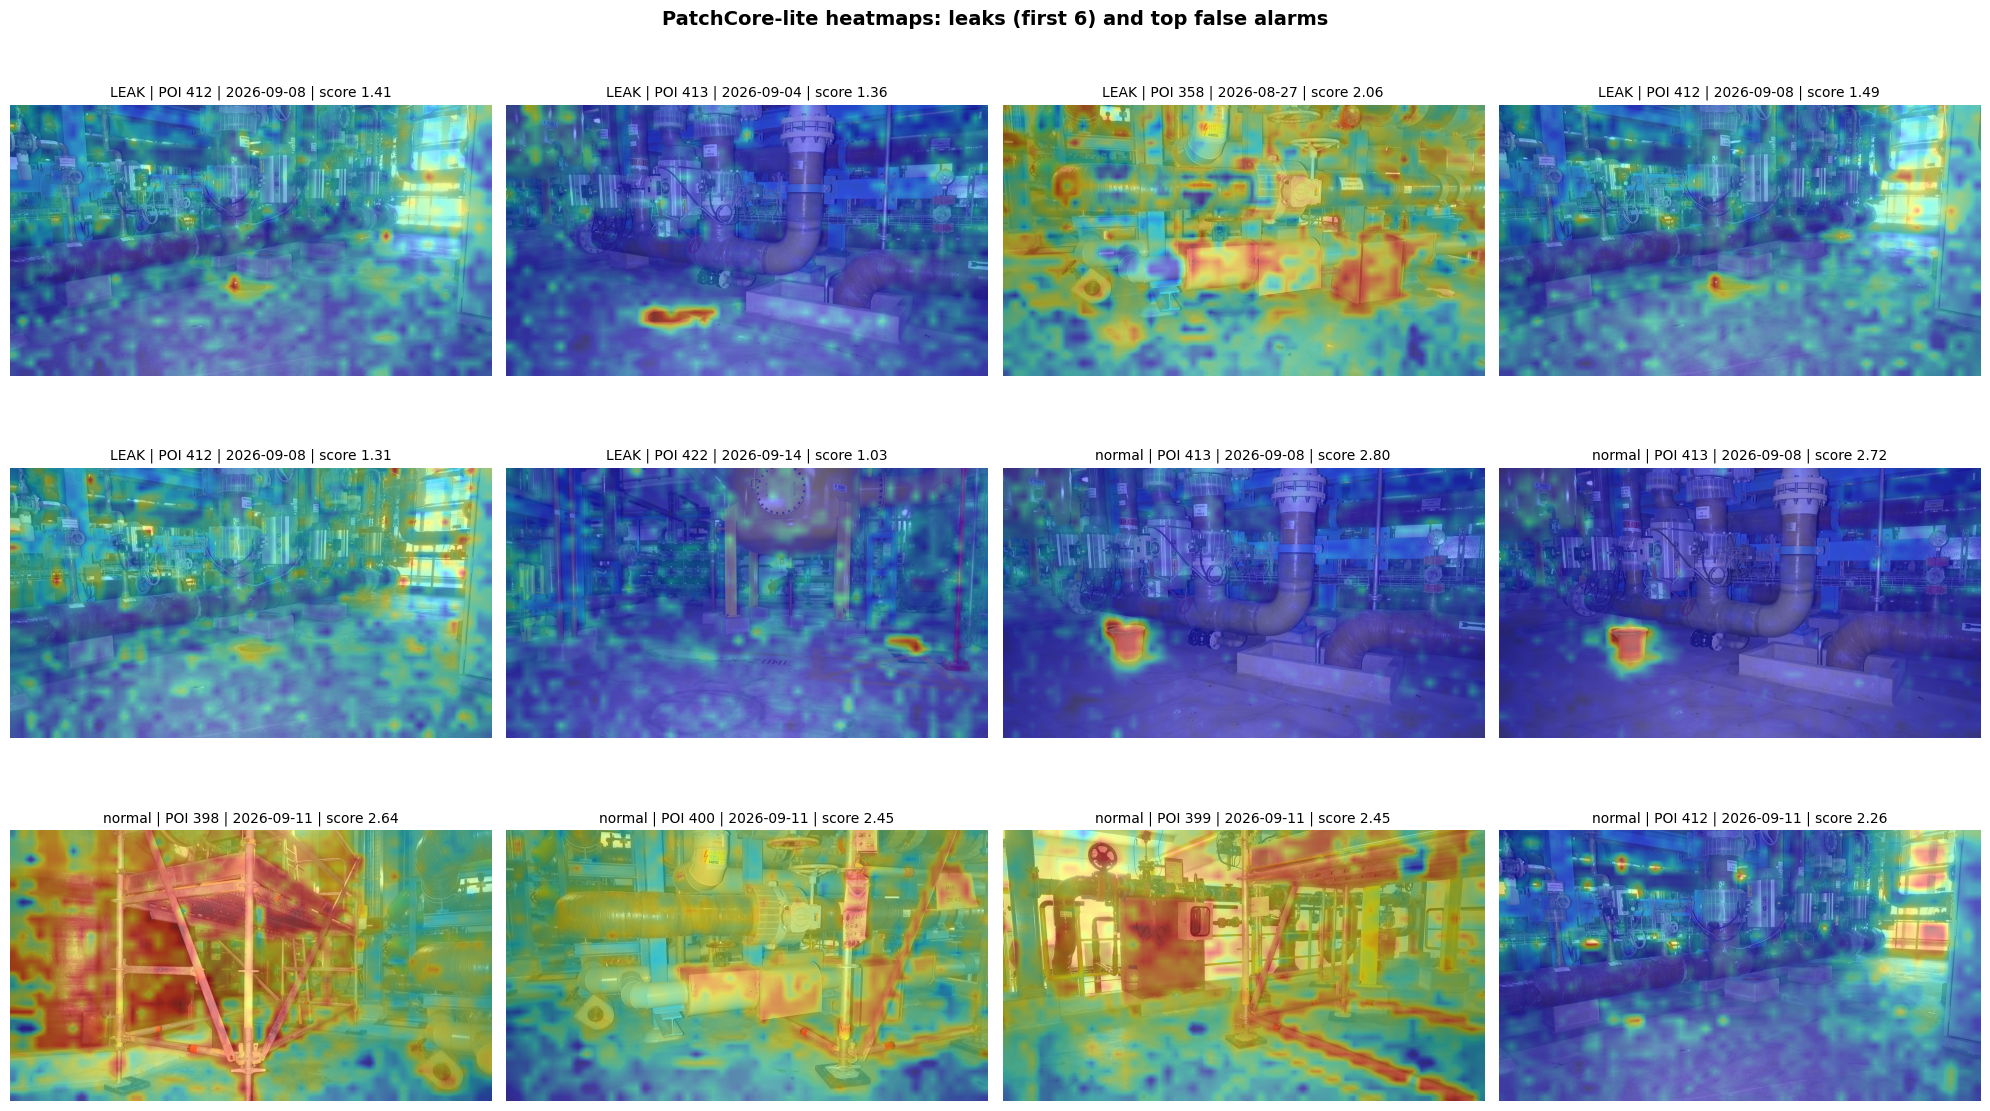

C2. DINOv2 PatchCore-lite: ROC-AUC=0.853 PR-AUC=0.165 | FP to catch 6/6=68 5/6=18 4/6=16 | 5% budget: 1/6 caught, 8 FP | leak ranks=[7, 11, 18, 20, 23, 74]


{'roc_auc': 0.8533333333333333,
 'pr_auc': 0.16496906279514975,
 'fp_to_catch_6_of_6': 68,
 'fp_to_catch_5_of_6': 18,
 'fp_to_catch_4_of_6': 16,
 'fp_to_catch_3_of_6': 15,
 'budget5_tp': 1,
 'budget5_fp': 8,
 'budget5_fn': 5,
 'budget5_tn': 142,
 'budget5_alerts': 9,
 'budget5_precision': 0.1111111111111111,
 'budget5_recall': 0.16666666666666666,
 'budget5_f1': 0.13333333333333333,
 'budget10_tp': 3,
 'budget10_fp': 15,
 'budget10_fn': 3,
 'budget10_tn': 135,
 'budget10_alerts': 18,
 'budget10_precision': 0.16666666666666666,
 'budget10_recall': 0.5,
 'budget10_f1': 0.25,
 'leak_ranks': [7, 11, 18, 20, 23, 74]}

In [0]:
# --- PatchCore-lite: patch-level anomaly detection ---
# Instead of comparing whole images, compare individual 14x14 patches to the
# POI's normal patch bank. Detects localized changes (e.g. a puddle in one corner)
# that might not shift the global embedding much.
MAX_BANK = 30000    # Cap on reference patches (subsampled if more) for speed
TOPK_FRAC = 0.01   # Score = mean distance of the top 1% most anomalous patches
PATCH_MAPS = {}     # Stores per-image spatial distance maps for heatmap visualization


def patch_nn_dist(i, ref):
    """For each patch in image i, find the distance to its nearest neighbor
    in the reference patch bank. Returns a distance array (one per query patch)."""
    # Build the reference patch bank from all normal reference images
    bank = np.concatenate([PATCHES[j] for j in ref]).astype(np.float32)
    if len(bank) > MAX_BANK:
        bank = bank[RNG.choice(len(bank), MAX_BANK, replace=False)]
    q = torch.from_numpy(PATCHES[i].astype(np.float32))
    b = torch.from_numpy(bank)
    # Compute nearest-neighbor distances in chunks of 10k to avoid OOM
    d = torch.full((len(q),), float("inf"))
    for s in range(0, len(b), 10000):
        d = torch.minimum(d, torch.cdist(q, b[s:s + 10000]).min(dim=1).values)
    return d.numpy()


raw_C2 = np.zeros(len(df))
t0 = time.time()
for i in range(len(df)):
    ref, _ = reference_idx(i)
    d = patch_nn_dist(i, ref)
    # Score = mean distance of the top 1% most anomalous patches (ignores normal-looking patches)
    k = max(1, int(len(d) * TOPK_FRAC))
    raw_C2[i] = float(np.sort(d)[-k:].mean())
    PATCH_MAPS[i] = d.reshape(GRIDS[i])
print(f"PatchCore-lite scored {len(df)} images in {time.time() - t0:.1f}s")

s_C2 = normalize_by_reference(raw_C2)

# --- Visualization: heatmaps showing WHERE in each image the anomaly is ---
# Red/yellow patches = high distance from normal = most changed vs. this POI's history
# Shows leak images first, then the top 6 false alarms for comparison
os.makedirs("/tmp/heatmaps", exist_ok=True)
show = list(np.where(y == 1)[0]) + [i for i in np.argsort(-s_C2) if y[i] == 0][:6]
fig, axes = plt.subplots(3, 4, figsize=(20, 12))
for ax, i in zip(axes.ravel(), show):
    img = Image.open(os.path.join(IMAGE_BASE_PATH, df.loc[i, "filename"])).convert("RGB")
    hm = np.asarray(Image.fromarray(PATCH_MAPS[i].astype(np.float32)).resize(img.size, Image.BILINEAR))
    ax.imshow(img); ax.imshow(hm, cmap="jet", alpha=0.45)
    ax.set_title(f"{'LEAK' if y[i] else 'normal'} | POI {poi_arr[i]} | {day_arr[i]} | score {s_C2[i]:.2f}", fontsize=10)
    ax.axis("off")
for ax in axes.ravel()[len(show):]:
    ax.axis("off")
plt.suptitle("PatchCore-lite heatmaps: leaks (first 6) and top false alarms", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig("/tmp/heatmaps/patchcore_heatmaps.png", dpi=80)
plt.show()

log_model("C2. DINOv2 PatchCore-lite", s_C2,
          {"approach": "patch distance to POI normals", "model": "facebook/dinov2-small patches, PatchCore-lite",
           "topk_frac": TOPK_FRAC, "max_bank": MAX_BANK, "score_normalization": "divide by reference median"},
          artifacts=["/tmp/heatmaps/patchcore_heatmaps.png"])

In [0]:
def pct_rank(s):
    """Convert raw scores to percentile ranks (0–1), making them comparable across models."""
    return pd.Series(s).rank(pct=True).values


# Ensemble: average the percentile ranks from B1 (hand-crafted feature anomaly)
# and C2 (DINOv2 patch-level anomaly). Both are unsupervised — no leak labels needed.
# Rank averaging is robust: it doesn't matter that B1 and C2 have different score scales.
s_D = (pct_rank(s_B1) + pct_rank(s_C2)) / 2
log_model("D. Ensemble B1 + C2", s_D, {"approach": "rank-average ensemble", "members": "B1,C2"})

D. Ensemble B1 + C2: ROC-AUC=0.840 PR-AUC=0.180 | FP to catch 6/6=89 5/6=18 4/6=12 | 5% budget: 2/6 caught, 8 FP | leak ranks=[8, 9, 15, 16, 22, 94]


{'roc_auc': 0.84,
 'pr_auc': 0.1796285702178151,
 'fp_to_catch_6_of_6': 89,
 'fp_to_catch_5_of_6': 18,
 'fp_to_catch_4_of_6': 12,
 'fp_to_catch_3_of_6': 12,
 'budget5_tp': 2,
 'budget5_fp': 8,
 'budget5_fn': 4,
 'budget5_tn': 142,
 'budget5_alerts': 10,
 'budget5_precision': 0.2,
 'budget5_recall': 0.3333333333333333,
 'budget5_f1': 0.25,
 'budget10_tp': 4,
 'budget10_fp': 15,
 'budget10_fn': 2,
 'budget10_tn': 135,
 'budget10_alerts': 19,
 'budget10_precision': 0.21052631578947367,
 'budget10_recall': 0.6666666666666666,
 'budget10_f1': 0.32,
 'leak_ranks': [8, 9, 15, 16, 22, 94]}

In [0]:
# --- Final side-by-side comparison of all models ---
cols = ["roc_auc", "pr_auc", "fp_to_catch_6_of_6", "fp_to_catch_5_of_6", "fp_to_catch_4_of_6",
        "budget5_tp", "budget5_fp", "budget10_tp", "budget10_fp", "budget10_precision", "budget10_f1", "leak_ranks"]
summary = pd.DataFrame(RESULTS).T[cols]
summary.columns = ["ROC-AUC", "PR-AUC", "FP to catch 6/6", "FP to catch 5/6", "FP to catch 4/6",
                   "Caught @5% budget", "FP @5% budget", "Caught @10% budget", "FP @10% budget",
                   "Precision @10%", "F1 @10%", "Leak ranks (of 157)"]
display(summary)

# Compare alert distribution per POI: best new model vs. current production model
# Uses a 10% false-alarm budget (threshold set from normal-image percentiles only)
best = max([k for k in RESULTS if k != "Current production model"], key=lambda k: RESULTS[k]["pr_auc"])
thr = np.percentile(SCORES.loc[SCORES.leaked == 0, best], 90)
per_poi = SCORES.assign(current_alert=df["current_alert"], best_alert=(SCORES[best] >= thr).astype(int)) \
    .groupby("poi").agg(images=("leaked", "size"), leaks=("leaked", "sum"),
                        current_alerts=("current_alert", "sum"), best_model_alerts=("best_alert", "sum"))
print(f"Alerts per POI — best model by PR-AUC: {best}")
display(per_poi.sort_values("current_alerts", ascending=False))

with mlflow.start_run(run_name="Summary - POI baseline experiments"):
    mlflow.log_table(summary.reset_index().rename(columns={"index": "model"}).astype(str), "summary.json")
    mlflow.log_table(per_poi.reset_index(), "alerts_per_poi.json")
    mlflow.log_table(SCORES, "all_scores.json")
    mlflow.log_param("best_model_by_pr_auc", best)

# Return structured results so this notebook can be called from a parent workflow
dbutils.notebook.exit(json.dumps({
    "summary": summary.reset_index().rename(columns={"index": "model"}).astype(str).to_dict(orient="records"),
    "best_model": best,
    "per_poi": per_poi.reset_index().astype(str).to_dict(orient="records"),
}))

In [0]:
import pickle, tempfile

tmpdir = tempfile.mkdtemp()

# --- Per-POI reference data (normal images only) ---
ref_data = {}
for poi in sorted(df["poi"].unique()):
    idx = np.where((poi_arr == poi) & normal_arr)[0]
    if len(idx) == 0:
        continue
    ref_data[int(poi)] = {
        "features": F[idx].astype(np.float32),
        "cls": CLS[idx].astype(np.float32),
        "patches": [PATCHES[j] for j in idx],
    }

# Per-POI median raw C2 scores (for normalization)
c2_medians = {}
for poi in sorted(df["poi"].unique()):
    idx = np.where((poi_arr == poi) & normal_arr)[0]
    if len(idx) > 0:
        c2_medians[int(poi)] = float(np.median(raw_C2[idx]))
c2_medians["_global"] = float(np.median(raw_C2[normal_arr]))

ref_path = os.path.join(tmpdir, "reference.pkl")
with open(ref_path, "wb") as fh:
    pickle.dump({"poi_data": ref_data, "c2_medians": c2_medians}, fh, protocol=4)

# Historical score distributions (for percentile ranking at inference time)
hist_path = os.path.join(tmpdir, "historical.pkl")
with open(hist_path, "wb") as fh:
    pickle.dump({"b1": s_B1.copy(), "c2": s_C2.copy()}, fh)

# Config
cfg = {"feature_cols": FEATURES, "min_ref": MIN_REF,
       "topk_frac": TOPK_FRAC, "max_bank": MAX_BANK,
       "imagenet_mean": MEAN.tolist(), "imagenet_std": STD.tolist()}
cfg_path = os.path.join(tmpdir, "config.json")
with open(cfg_path, "w") as fh:
    json.dump(cfg, fh)

# Save DINOv2 model weights
dino_path = os.path.join(tmpdir, "dino_model")
dino.save_pretrained(dino_path)

for root, _, files in os.walk(tmpdir):
    for f in files:
        fp = os.path.join(root, f)
        print(f"  {os.path.relpath(fp, tmpdir)}: {os.path.getsize(fp)/1e6:.1f} MB")
print(f"\nArtifacts ready in {tmpdir}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  reference.pkl: 210.4 MB
  historical.pkl: 0.0 MB
  config.json: 0.0 MB
  dino_model/model.safetensors: 88.2 MB
  dino_model/config.json: 0.0 MB

Artifacts ready in /tmp/tmplrxiunqf


In [0]:
class LeakDetectionEnsemble(mlflow.pyfunc.PythonModel):
    """Model D: unsupervised ensemble of B1 (POI-relative feature anomaly)
    and C2 (DINOv2 PatchCore-lite), fused via rank averaging.
    Input:  DataFrame with [image_path: str, poi_id: int]
    Output: DataFrame with [anomaly_score, b1_score, c2_score, b1_rank, c2_rank]
    """

    def load_context(self, context):
        import pickle, json, torch
        from transformers import AutoModel
        with open(context.artifacts["config"]) as f:
            self.cfg = json.load(f)
        with open(context.artifacts["reference"], "rb") as f:
            d = pickle.load(f)
            self.poi_data, self.c2_medians = d["poi_data"], d["c2_medians"]
        with open(context.artifacts["historical"], "rb") as f:
            self.hist = pickle.load(f)
        torch.set_grad_enabled(False)
        self.dino = AutoModel.from_pretrained(context.artifacts["dino_model"]).eval()
        self.MEAN = np.array(self.cfg["imagenet_mean"])
        self.STD  = np.array(self.cfg["imagenet_std"])

    # --- helpers ---
    def _ref(self, poi_id):
        k = int(poi_id)
        if k in self.poi_data and len(self.poi_data[k]["features"]) >= self.cfg["min_ref"]:
            return self.poi_data[k], k
        if not hasattr(self, "_glob"):
            self._glob = {
                "features": np.concatenate([v["features"] for v in self.poi_data.values()]),
                "cls":      np.concatenate([v["cls"]      for v in self.poi_data.values()]),
                "patches":  [p for v in self.poi_data.values() for p in v["patches"]],
            }
        return self._glob, "_global"

    def _features(self, path):
        from PIL import Image; from scipy import ndimage
        img = Image.open(path).convert("RGB"); w, h = img.size
        fl = np.array(img.crop((0, int(h*0.4), w, h)))
        gray = fl.astype(float).mean(2)
        r,g,b = [fl[:,:,c].astype(float) for c in range(3)]
        mx = np.maximum(np.maximum(r,g),b); mn = np.minimum(np.minimum(r,g),b)
        s_ch = np.where(mx>0,(mx-mn)/np.maximum(mx,1e-9),0); v_ch = mx
        dt = max(np.median(gray)*0.75,20); dk = (gray<dt).astype(np.int32)
        lab,n = ndimage.label(dk)
        sz = ndimage.sum(dk,lab,range(1,n+1)) if n else []
        lap = ndimage.laplace(gray)
        lm = ndimage.uniform_filter(gray,15); lsq = ndimage.uniform_filter(gray**2,15)
        edges = np.hypot(ndimage.sobel(gray,1),ndimage.sobel(gray,0))
        em = edges>np.percentile(edges,85)
        bm = ndimage.binary_dilation(dk>0,iterations=5)&~(dk>0)
        yy = .2126*r/255+.7152*g/255+.0722*b/255
        L = np.where(yy>.008856,116*np.cbrt(yy)-16,903.3*yy)
        return np.array([v_ch.mean(),v_ch.std(),dk.mean(),
            int(sum(1 for s in sz if s>dk.size*.002)),
            np.var(lap),np.mean(lsq-lm**2),em.mean(),
            (em&bm).sum()/max(bm.sum(),1),
            np.mean(np.abs(L-np.median(L))),
            s_ch[dk>0].mean() if dk.sum() else 0.], dtype=np.float64)

    def _embed(self, path):
        import torch; from PIL import Image
        img = Image.open(path).convert("RGB"); w,h = img.size
        s = 448/min(w,h)
        nw,nh = max(14,round(w*s/14)*14), max(14,round(h*s/14)*14)
        arr = (np.asarray(img.resize((nw,nh),Image.BICUBIC),dtype=np.float32)/255-self.MEAN)/self.STD
        x = torch.from_numpy(arr.transpose(2,0,1)).float().unsqueeze(0)
        out = self.dino(pixel_values=x).last_hidden_state[0]
        cls = torch.nn.functional.normalize(out[0],dim=0).numpy()
        pts = torch.nn.functional.normalize(out[1:],dim=1).half().numpy()
        return cls, pts

    def _b1(self, feats, ref):
        R = ref["features"]; med = np.median(R,0)
        mad = 1.4826*np.median(np.abs(R-med),0)
        sc = np.where(mad>1e-9,mad,R.std(0)+1e-9)
        z = np.clip((feats-med)/sc,-10,10)
        return float(np.sqrt(np.mean(z**2)))

    def _c2(self, pts, ref, key):
        import torch
        bank = np.concatenate(ref["patches"]).astype(np.float32)
        mb = self.cfg["max_bank"]
        if len(bank)>mb:
            bank = bank[np.random.default_rng(42).choice(len(bank),mb,replace=False)]
        q = torch.from_numpy(pts.astype(np.float32)); b = torch.from_numpy(bank)
        d = torch.full((len(q),),float("inf"))
        for s in range(0,len(b),10000):
            d = torch.minimum(d,torch.cdist(q,b[s:s+10000]).min(1).values)
        d = d.numpy(); k = max(1,int(len(d)*self.cfg["topk_frac"]))
        raw = float(np.sort(d)[-k:].mean())
        med = self.c2_medians.get(key, self.c2_medians.get("_global",1.0))
        return raw/(med+1e-9)

    def _prank(self, val, arr):
        return float((arr<=val).sum())/len(arr)

    def predict(self, context, model_input, params=None):
        rows = []
        for _, r in model_input.iterrows():
            ref, key = self._ref(r["poi_id"])
            feats = self._features(r["image_path"])
            cls, pts = self._embed(r["image_path"])
            b1 = self._b1(feats, ref)
            c2 = self._c2(pts, ref, key)
            br = self._prank(b1, self.hist["b1"])
            cr = self._prank(c2, self.hist["c2"])
            rows.append({"anomaly_score":(br+cr)/2, "b1_score":b1, "c2_score":c2,
                         "b1_rank":br, "c2_rank":cr})
        return pd.DataFrame(rows)

# --- Log model ---
mlflow.set_registry_uri("databricks-uc")
example = pd.DataFrame({"image_path": [os.path.join(IMAGE_BASE_PATH, df.iloc[0]["filename"])],
                         "poi_id": [int(df.iloc[0]["poi"])]})
sig = mlflow.models.infer_signature(
    example,
    pd.DataFrame([{"anomaly_score": .5, "b1_score": 1., "c2_score": 1., "b1_rank": .5, "c2_rank": .5}]),
)

with mlflow.start_run(run_name="Model D — Champion Registration") as run:
    mlflow.log_params({"model": "Ensemble B1+C2 (rank-average)",
                       "b1": "POI-relative feature anomaly", "c2": "DINOv2 PatchCore-lite",
                       "num_images": len(df), "num_leaks": N_LEAKS})
    for k, v in RESULTS["D. Ensemble B1 + C2"].items():
        if k != "leak_ranks" and v is not None and np.isfinite(float(v)):
            mlflow.log_metric(k, float(v))

    model_info = mlflow.pyfunc.log_model(
        python_model=LeakDetectionEnsemble(),
        artifact_path="model",
        artifacts={"config": cfg_path, "reference": ref_path,
                   "historical": hist_path, "dino_model": dino_path},
        signature=sig, input_example=example,
        pip_requirements=["torch", "torchvision", "transformers",
                          "numpy", "scipy", "Pillow", "pandas"],
    )
    print(f"Model logged: {model_info.model_uri}")
    print(f"Run ID: {run.info.run_id}")

# --- Register to Unity Catalog ---
MODEL_NAME = "stable_classic_wg38i9_catalog.westlake_gas_leakage_2.leak_detection_model"
mv = mlflow.register_model(model_info.model_uri, MODEL_NAME)
print(f"Registered {MODEL_NAME} v{mv.version}")

client = mlflow.MlflowClient()
client.set_registered_model_alias(MODEL_NAME, "Champion", mv.version)
client.update_registered_model(MODEL_NAME, description=(
    "Unsupervised ensemble (Model D) for liquid leak detection from plant inspection images. "
    "Combines B1 (POI-relative feature anomaly — 10 hand-crafted features compared to each POI's normal history) "
    "and C2 (DINOv2 PatchCore-lite — patch-level embedding distances to POI normals), "
    "fused via rank-average. Evaluation on 156 images (6 leaks, leave-one-day-out): "
    "ROC-AUC=0.840, PR-AUC=0.180, catches 4/6 leaks at 10% FP budget (F1=0.32). "
    "Fully unsupervised — no leak labels needed to train. "
    "Input: image_path (str) + poi_id (int). Output: anomaly_score (0–1)."
))
client.update_model_version(MODEL_NAME, mv.version,
    description=f"Champion v{mv.version} — Model D Ensemble B1+C2, ROC-AUC=0.840, PR-AUC=0.180")
print(f"Champion alias set on v{mv.version}")
print(f"\n{'='*60}\nMODEL D REGISTERED AS CHAMPION\n{'='*60}")

/local_disk0/.ephemeral_nfs/envs/pythonEnv-daf9d918-1816-472f-902a-2adc0442c28f/lib/python3.12/site-packages/mlflow/pyfunc/utils/data_validation.py:187: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(
/local_disk0/.ephemeral_nfs/envs/pythonEnv-daf9d918-1816-472f-902a-2adc0442c28f/lib/python3.12/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns a

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

Model logged: models:/m-a1d02a2e75dc41649f55cf9fbaea29ef
Run ID: db63beefecbf48ca8eabaedfef3285a0


Registered model 'stable_classic_wg38i9_catalog.westlake_gas_leakage_2.leak_detection_model' already exists. Creating a new version of this model...


Uploading artifacts:   0%|          | 0/17 [00:00<?, ?it/s]

🔗 Created version '2' of model 'stable_classic_wg38i9_catalog.westlake_gas_leakage_2.leak_detection_model': https://fevm-stable-classic-wg38i9.cloud.databricks.com/explore/data/models/stable_classic_wg38i9_catalog/westlake_gas_leakage_2/leak_detection_model/version/2?o=7474649345910036


Registered stable_classic_wg38i9_catalog.westlake_gas_leakage_2.leak_detection_model v2
Champion alias set on v2

MODEL D REGISTERED AS CHAMPION
